In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from adjustText import adjust_text
from dotenv import dotenv_values
from matplotlib import pyplot as plt

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Plotting defaults
MM = 1/25.4
RCPARAMS = '../../../resources/figures.mplstyle'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'sexual_dimorphism'
FIGUREDIR = DATADIR / 'publication' / 'Fig_04'

# notebook-specific constants
N_SIG_GENES_THRESHOLD = 100

In [12]:
# Load cell-type sexual dimorphism metrics
fp_sd_metrics = OUTDIR / 'L4_sd_metrics.csv'
df_sd_metrics = pd.read_csv(fp_sd_metrics, index_col=0)
df_sd_metrics.head(3)

,n_DEGs,pct_Female,sLISI_Q1,sLISI_Q2,sLISI_Q3,sex_ratio_deviance
celltype_ID,,,,,,
Gl4-220,561,0.325898,0.310767,0.808747,0.981644,0.174102
Gl4-140,539,0.409053,0.545246,0.877870,0.982116,0.090947
Gb4-438,409,0.333582,0.358622,0.733945,0.923493,0.166418


### Flag those that are dimorphic

In [18]:
# >= 100 DEGs is sexually dimorphic or sex dominant
df_sd_metrics['is_dimorphic'] = (
    (df_sd_metrics['n_DEGs'] >= N_SIG_GENES_THRESHOLD)
    | (df_sd_metrics['pct_Female'] >= 0.95)
    | (df_sd_metrics['pct_Female'] <= 0.05)
    )
print(df_sd_metrics['is_dimorphic'].sum(), 'celltypes are sexually dimorphic.')

24 celltypes are sexually dimorphic.


In [19]:
# We manually override NN4-22 as dimorphic as it is a poorly defined subtype
df_sd_metrics.loc['NN4-22', 'is_dimorphic'] = False

### Subplot C: Scatter Plot

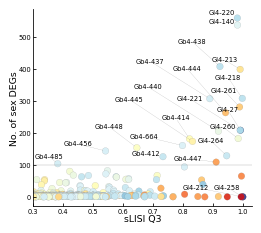

In [20]:
plt.close('all')
with plt.style.context(RCPARAMS):
    
    # Create mosaic layout: one main scatter plot with a narrow colorbar on the right
    mosaic = [['scatter']]
    
    fig, axes = plt.subplot_mosaic(
        mosaic,
        figsize=(68*MM, 58*MM),
    )
    
    ax = axes['scatter']
    
    x = df_sd_metrics['sLISI_Q3']
    y = np.clip(df_sd_metrics['n_DEGs'], 0, 600)
    c = df_sd_metrics['pct_Female']  # must be numeric
    l = df_sd_metrics.index.tolist()
    s = df_sd_metrics['is_dimorphic']

    # Scatter plot
    cmap = plt.get_cmap('RdYlBu').reversed()
    sc = ax.scatter(
        x, y, c=c, cmap=cmap,
        edgecolor='grey', linewidths=0.1,
        vmin=0, vmax=1, s=25
    )

    # Colorbar in mosaic subplot
    # cbar = fig.colorbar(
    #     sc, ax=ax,
    #     location='right', fraction=0.03, pad=0.02
    # )
    # cbar.set_ticks([])
    # cbar.set_ticklabels([])
    # # cbar.set_label('Sex Ratio', fontsize=7)

    # Aesthetics
    ax.grid(False)
    ax.set_xlabel('sLISI Q3')
    ax.set_ylabel('No. of sex DEGs')

    # ax.axvline(x=SLISI_SEX_THRESOLD, c='grey', linestyle='-', linewidth=0.2)
    ax.axhline(y=N_SIG_GENES_THRESHOLD, c='grey', linestyle='-', linewidth=0.2)

    # Clean up axes
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(0.3, 1.03)
    ax.set_ylim(-30, None)

    # Annotate selected points
    texts = []
    for xi, yi, label, flag in zip(x, y, l, s):
        if flag:
            texts.append(ax.text(
                xi, yi,
                str(label),
                fontsize=5,
                ha='right',
                va='bottom',
                color='black'
            ))

    # Adjust label positions to avoid overlap
    adjust_text(
        texts,
        x=x[s.astype(bool)],
        y=y[s.astype(bool)],
        ax=ax,
        expand_points=(3, 3),
        expand_text=(2.5, 2.5),
        force_points=0,
        force_text=2.0,
        only_move='y+x-',
        arrowprops=dict(
            arrowstyle='-',
            color="#3C3C3C",
            lw=0.1,
            alpha=0.7
        )
    )
    fig.subplots_adjust(left=0.15, bottom=0.1, top=1, right=1)
    fig.savefig(FIGUREDIR / 'subplot_c_metric_scatter.pdf', dpi=600, transparent=True)
    plt.show()


### Subplot D: dendrogram?

In [23]:
# Load control anndata
fp_anndata = DATADIR / '9_objects' / 'singlecell' / 'hypomap3d_singlecell_control.h5ad'
scdata = sc.read_h5ad(fp_anndata, backed='r')

In [55]:
sexually_dimorphic_clusters = df_sd_metrics[df_sd_metrics['is_dimorphic']].index.tolist()
sexually_dimorphic_clusters = sorted(sexually_dimorphic_clusters, key=lambda x: int(x.split('-')[-1]))

# Keep only neuronal
sexually_dimorphic_clusters = [x for x in sexually_dimorphic_clusters if not x.startswith('NN')]

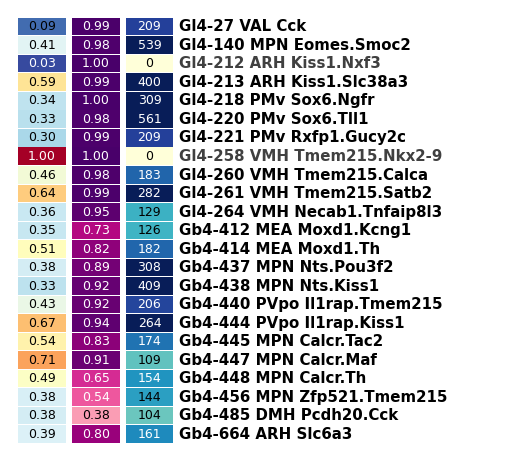

In [56]:
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize

def hide_axes(ax):
    ax.set_xticks([])        # remove x ticks
    ax.set_yticks([])        # remove y ticks
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)

desc_name_map = scdata.obs[["L4_ID", "L4_descr"]].set_index("L4_ID", drop=True)["L4_descr"].drop_duplicates().to_dict()

ratio_cmap = plt.get_cmap('RdYlBu').reversed()
norm_ratio = Normalize(vmin=0, vmax=1)

sLISI_cmap = plt.get_cmap('RdPu')
norm_sLISI = Normalize(vmin=0, vmax=1)

n_sig_cmap = plt.get_cmap('YlGnBu')
norm_n_sig = Normalize(vmin=0, vmax=250)

plt.close('all')
with plt.style.context(RCPARAMS):

    mosaic = [
        [f'ratio_{i}'] + [f'sLISI_{i}'] + [f'n_DEGs_{i}'] + [f'label_{i}']
        for i in range(len(sexually_dimorphic_clusters))
    ]

    # Side split between dendogram and cluste information
    fig, axes = plt.subplot_mosaic(
        mosaic, 
        figsize=(70*MM, 60*MM),
        gridspec_kw={
            "width_ratios": [1, 1, 1, 7],   # left column twice as wide as right
            "wspace": 0.05, "hspace": 0.05
        },
        dpi=180
    )
    
    # Right: 4 feature columns × n_leaves rows ----------------------------------- #
    for i, cluster in enumerate(sexually_dimorphic_clusters):
        ax1, ax2, ax3, ax4 = axes[f'ratio_{i}'], axes[f'sLISI_{i}'], axes[f'n_DEGs_{i}'], axes[f'label_{i}']

        # Sex Ratio ------------------------------------------------------------------ #    
        val = df_sd_metrics.loc[cluster, 'pct_Female']
        fill_color = ratio_cmap(norm_ratio(val))
        ax1.add_patch(Rectangle(
            (0, 0), 1, 1,
            color=fill_color, lw=0, zorder=0
        ))
        extreme = np.abs(val - 0.5) >= 0.45
        ax1.text(0.5, 0.5, f"{val:.2f}", va='center', ha='center', fontsize=5, color="#FFFFFF" if extreme else '#000000')
        hide_axes(ax1)
        
        # sLISI Score ---------------------------------------------------------------- #
        val = df_sd_metrics.loc[cluster, 'sLISI_Q3']
        fill_color = sLISI_cmap(norm_sLISI(val))
        ax2.add_patch(Rectangle(
            (0, 0), 1, 1,
            color=fill_color, lw=0, zorder=0
        ))
        ax2.text(0.5, 0.5, f"{val:.2f}", va='center', ha='center', fontsize=5, color="#FFFFFF" if val > 0.5 else '#000000')
        hide_axes(ax2)
        
        # No. of Significant Genes --------------------------------------------------- #
        val = df_sd_metrics.loc[cluster, 'n_DEGs']
        fill_color = n_sig_cmap(norm_n_sig(val))
        ax3.add_patch(Rectangle(
            (0, 0), 1, 1,
            color=fill_color, lw=0, zorder=0
        ))
        ax3.text(0.5, 0.5, f"{val}", va='center', ha='center', fontsize=5, color="#FFFFFF" if val > 150 else '#000000')
        hide_axes(ax3)
        
        # Text Labels ---------------------------------------------------------------- #

        # ax4 = plt.subplot(gs_right[i, 3], sharex= ax4_master)
        desc_name = desc_name_map[cluster]
        ax4.text(0, 0.5, desc_name, va='center', ha='left', fontsize=6, weight='bold', color="#404040" if val == 0 else "#000000")
        hide_axes(ax4)

    fig.subplots_adjust(left=0, bottom=0, top=1, right=1)
    fig.savefig(FIGUREDIR / 'subplot_d_sd_cluster_table.pdf', transparent=True)
    plt.show()

### Create colorbars

In [34]:
ratio_cmap = plt.get_cmap('RdYlBu').reversed()
norm_ratio = Normalize(vmin=0, vmax=1)

sLISI_cmap = plt.get_cmap('RdPu')
norm_sLISI = Normalize(vmin=0, vmax=1)

n_sig_cmap = plt.get_cmap('YlGnBu')
norm_n_sig = Normalize(vmin=0, vmax=250)

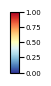

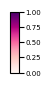

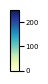

In [51]:
figsize = (3 * MM, 20 * MM)

for cmap, norm, name in [
    (ratio_cmap, norm_ratio, 'pct_female'),
    (sLISI_cmap, norm_sLISI, 'sLISI'),
    (n_sig_cmap, norm_n_sig, 'n_degs'),
]:
    fig, ax = plt.subplots(figsize=figsize)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cb = plt.colorbar(sm, orientation="vertical", cax=ax)

    cb.ax.tick_params(labelsize=5, pad=1)      # Tick label size
    cb.set_label(cb.ax.get_ylabel(), fontsize=5)  # If you have a label
    
    # fig.subplots_adjust(left=0, bottom=0, top=1, right=1.5)
    
    fig.savefig(
        FIGUREDIR / f"colorbar_{name}.pdf",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
    )
    plt.show()